# T31: wavelet determinism + result-changing comb-fit / CWT speed-ups

Regenerates every figure in `README.md` from `runs/t31/` (scorecard outputs and `profile_pipeline.py` timings copied from the overnight session; see README *Reproduce* to rebuild them) and `data/`. All plotting code lives in `analysis.py`.

In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
HERE = Path.cwd()
ROOT = HERE.parents[1]
sys.path.insert(0, str(HERE))
import analysis as A
SCR = ROOT / 'runs' / 't31'
FIG = HERE / 'figures'
met = A.collect_metrics(SCR)
tim = A.timing_summary(A.collect_profiles(SCR))
met[['run','mode','success','correct','diffrot','wrong','none','wavelet_recall','wavelet_top1_success']].round(3)

,run,mode,success,correct,diffrot,wrong,none,wavelet_recall,wavelet_top1_success
0,A,assigned,0.147,0.109,0.038,0.055,0.789,0.490,0.192
1,A,fullyear,0.251,0.198,0.053,0.088,0.647,0.570,0.265
2,A_rep,assigned,0.147,0.109,0.038,0.055,0.789,0.490,0.192
3,A_rep,fullyear,0.251,0.198,0.053,0.088,0.647,0.570,0.265
4,main,assigned,0.147,0.109,0.038,0.055,0.789,0.490,0.192
5,main,fullyear,0.251,0.198,0.053,0.088,0.647,0.570,0.265
6,v_local__dec,assigned,0.152,0.115,0.037,0.066,0.771,0.485,0.192
7,v_local__dec,fullyear,0.260,0.204,0.056,0.088,0.637,0.566,0.264
8,v_local_screen1__lean,assigned,0.145,0.109,0.036,0.054,0.792,0.490,0.192
9,v_local_screen1__lean,fullyear,0.248,0.195,0.053,0.083,0.655,0.570,0.265


## Part A: identity checks
Green rows are bit-identical; orange rows differ only in the last digits of `methods.wavelet.top1`.

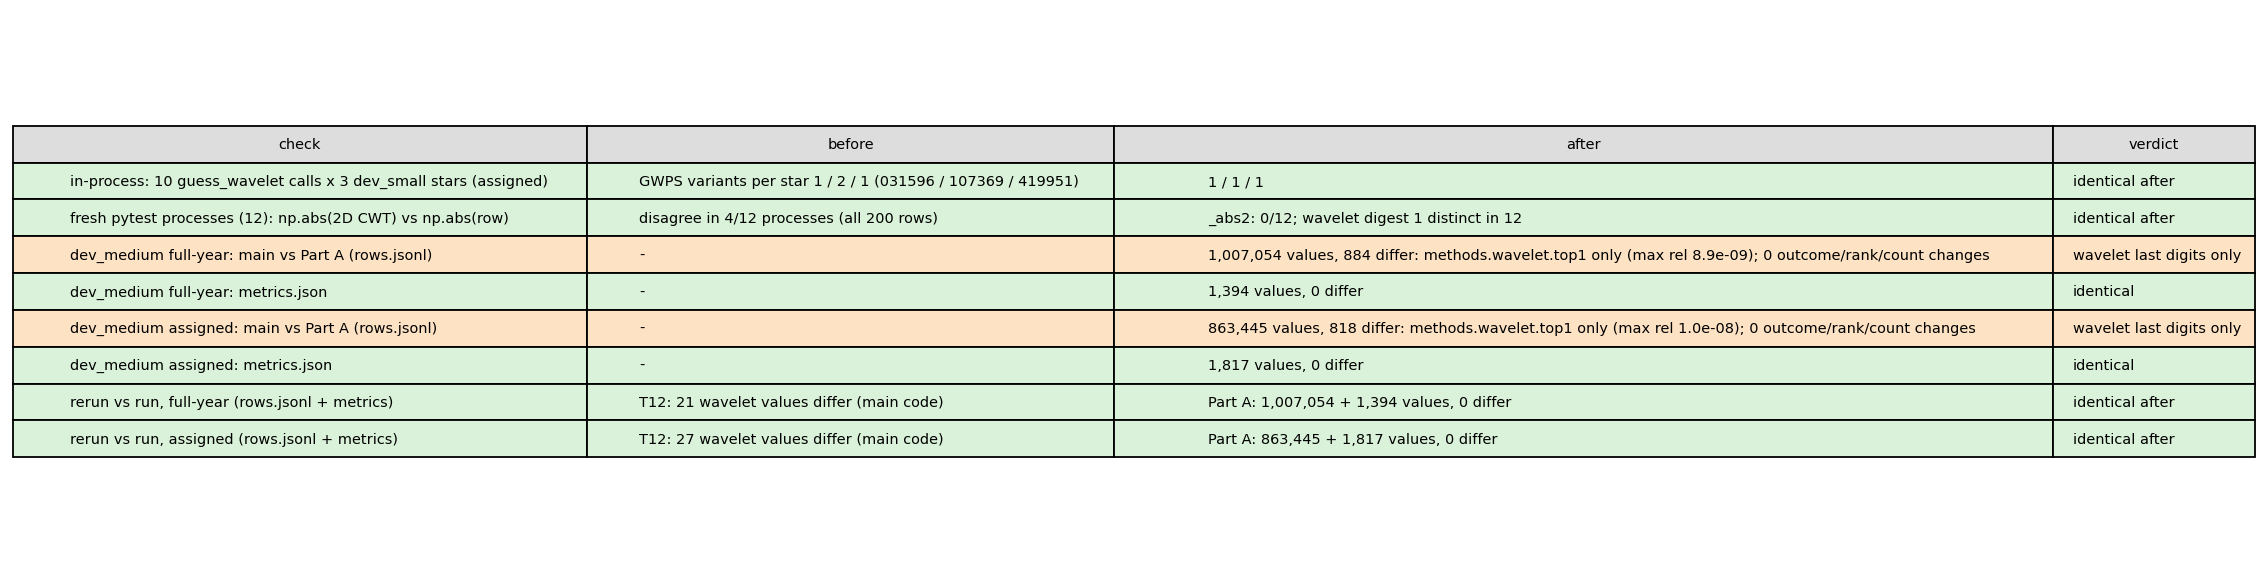

In [2]:
ident = pd.read_csv(SCR / 'identity_partA.csv')
A.fig_identity(ident, FIG / 'fig_identity_partA.png')
display(Image(FIG / 'fig_identity_partA.png'))

## Part B: timing (serial, 15-star set, rounds 2-3)
Mean seconds per star per stage; `main` = pre-T31 code, `lsq` = Part A code with the default comb fit.

In [3]:
tim[['comb','cwt','mode','fit','guess_wavelet','total']].round(3)

,comb,cwt,mode,fit,guess_wavelet,total
0,local,full,assigned,0.063,0.173,0.345
1,local,full,fullyear,0.085,0.301,0.585
2,local_screen1,full,assigned,0.212,0.172,0.496
3,local_screen1,full,fullyear,0.241,0.298,0.747
4,local_screen2,full,assigned,0.311,0.171,0.592
5,local_screen2,full,fullyear,0.381,0.303,0.890
6,local_warm,full,assigned,0.556,0.171,0.839
7,local_warm,full,fullyear,0.723,0.302,1.233
8,local_warm_tol4,full,assigned,0.380,0.173,0.667
9,local_warm_tol4,full,fullyear,0.496,0.302,0.996


### Accuracy vs time frontier
Top: success; bottom: wrong rate. The red star / dotted line is current main.

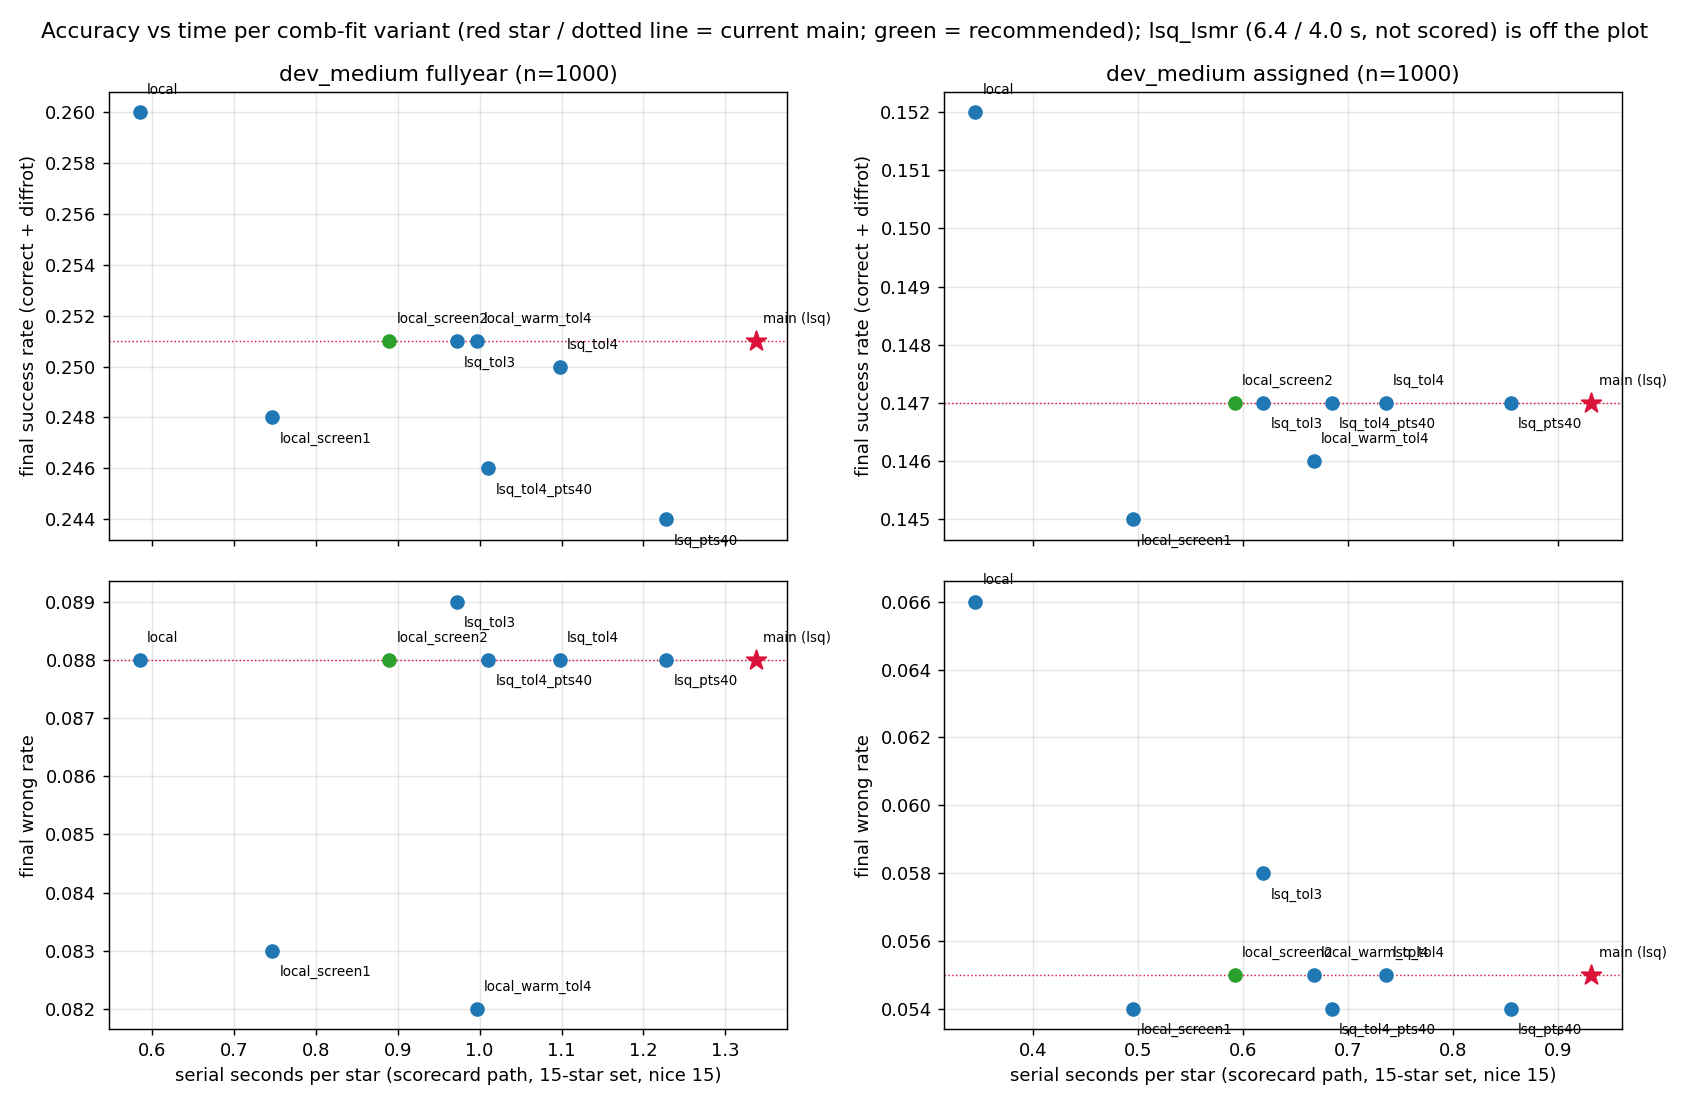

In [4]:
A.fig_frontier(met, tim, FIG / 'fig_frontier.png')
display(Image(FIG / 'fig_frontier.png'))

Same, against the comb-fit stage time only (the part the comb variants change).

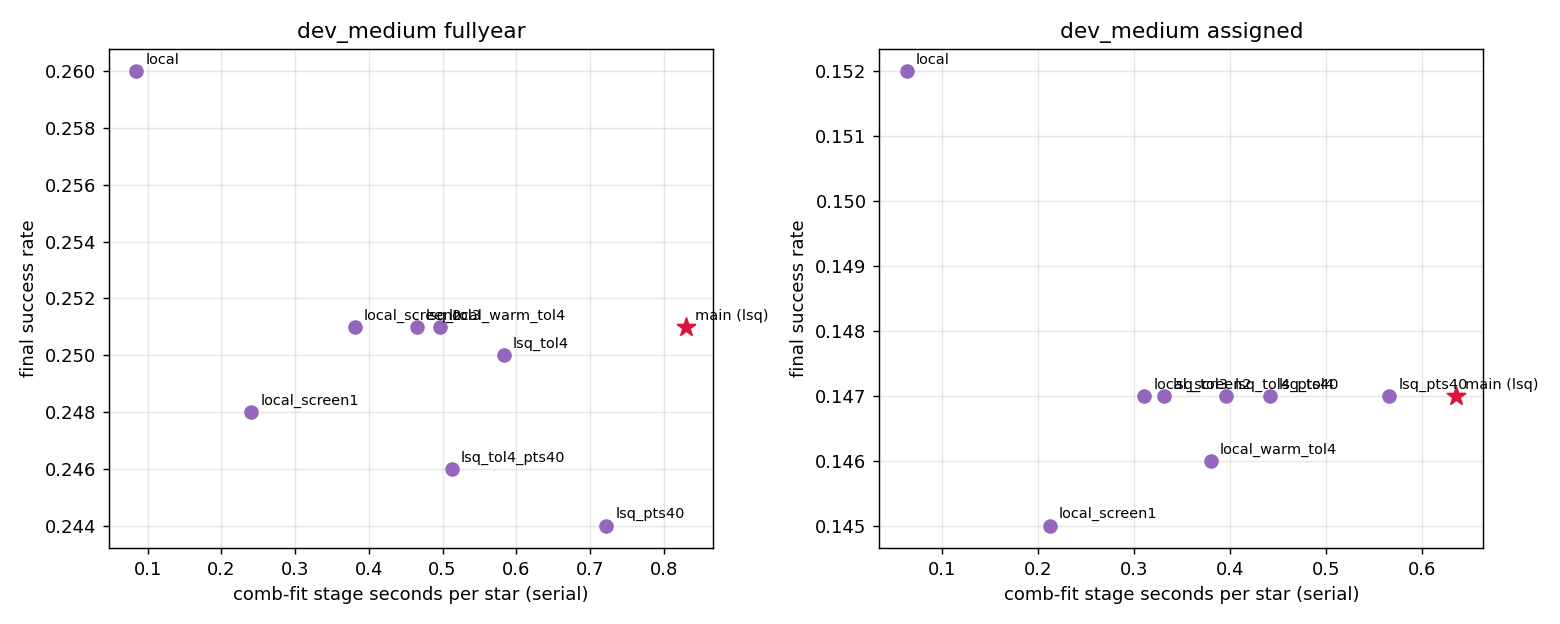

In [5]:
A.fig_fit_frontier(met, tim, FIG / 'fig_frontier_fit_stage.png')
display(Image(FIG / 'fig_frontier_fit_stage.png'))

### Success by period bin: main vs local_screen2 (recommended), local, lsq_tol3

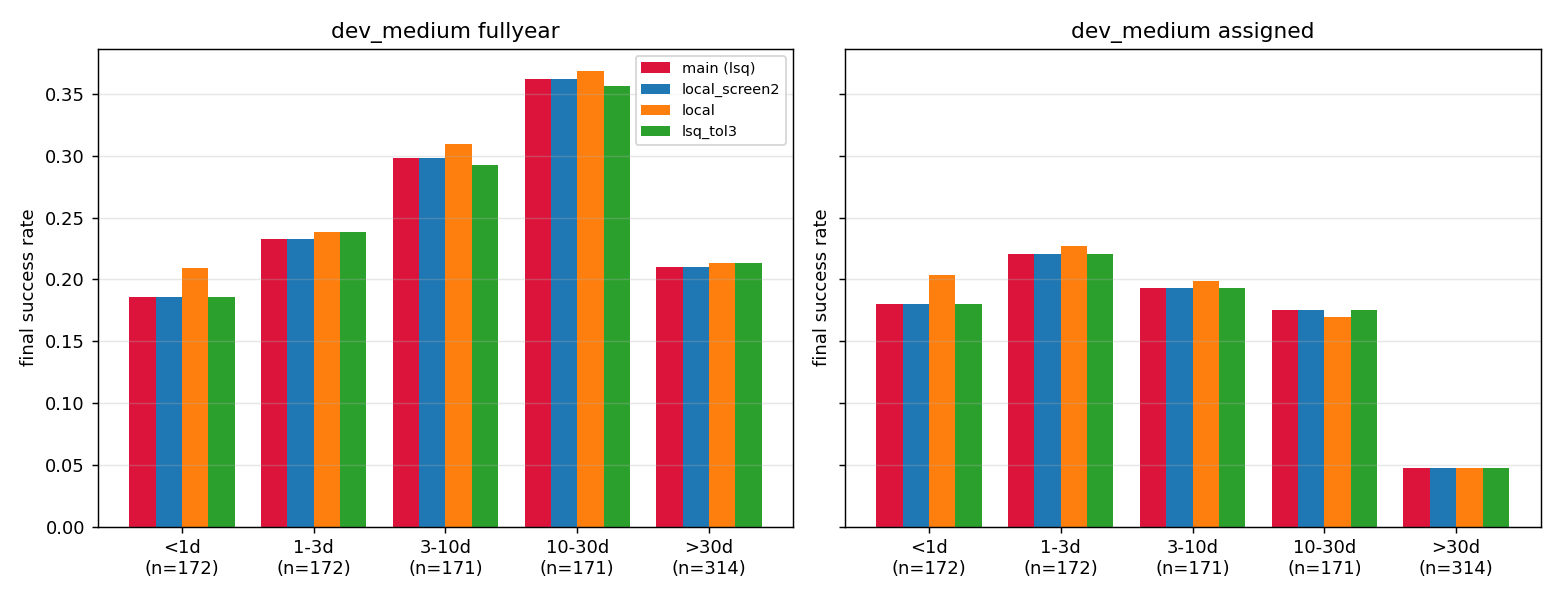

In [6]:
A.fig_by_bin(met, ['v_local_screen2', 'v_local__dec', 'v_lsq_tol3__n100'], FIG / 'fig_success_by_bin.png')
display(Image(FIG / 'fig_success_by_bin.png'))

### Per-stage time: pre-T31 main, Part A, local_screen2

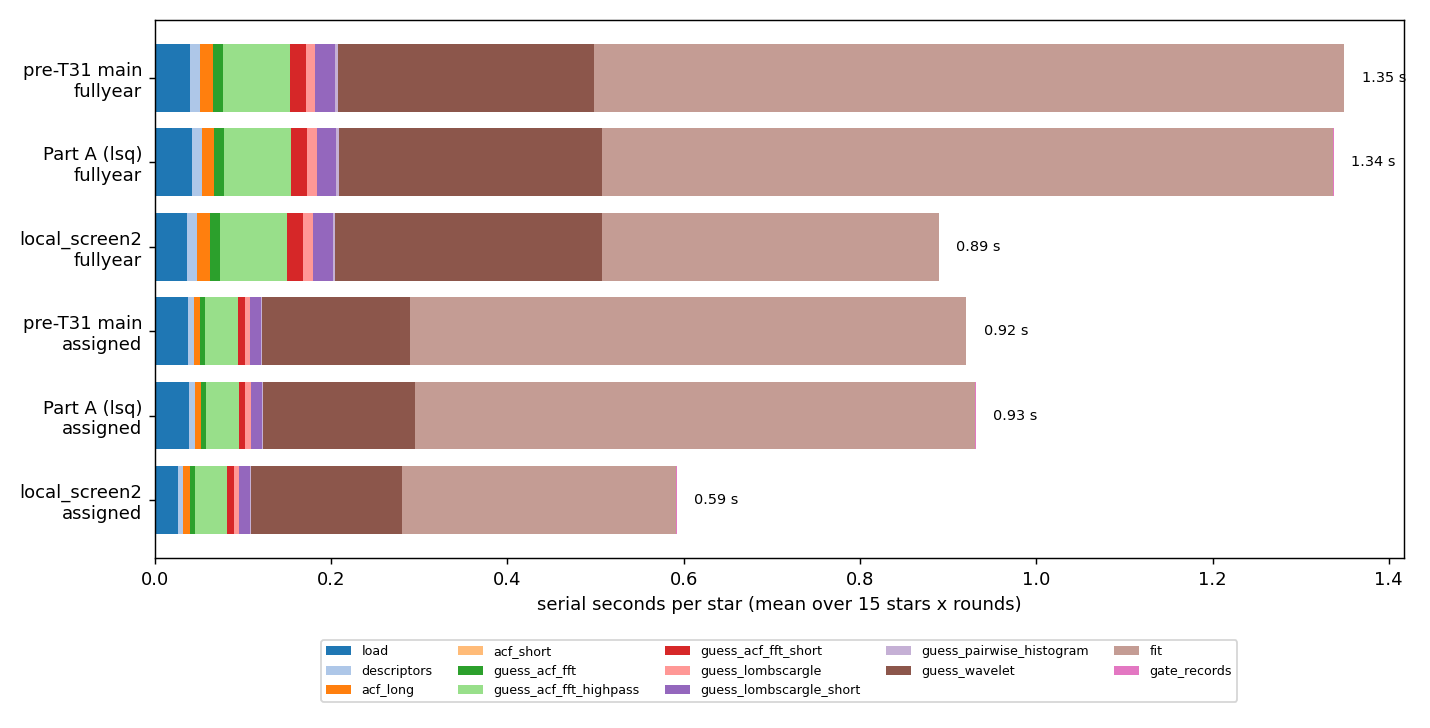

In [7]:
A.fig_stage_breakdown(tim, 'local_screen2', FIG / 'fig_stage_breakdown.png')
display(Image(FIG / 'fig_stage_breakdown.png'))

### The screen threshold
Gates failed under the local fit, for candidates the lsq fit passes (green) or fails (grey). local_screen2 refits everything left of the solid line with lsq.

,mode,k,refits_per_star,recall_lsq_pass,recall_main_selected
0,fullyear,1,5.156,0.976234,0.974504
1,fullyear,2,9.936,0.996344,0.997167
2,assigned,1,5.634,0.982405,0.985782
3,assigned,2,9.278,0.997067,1.000000


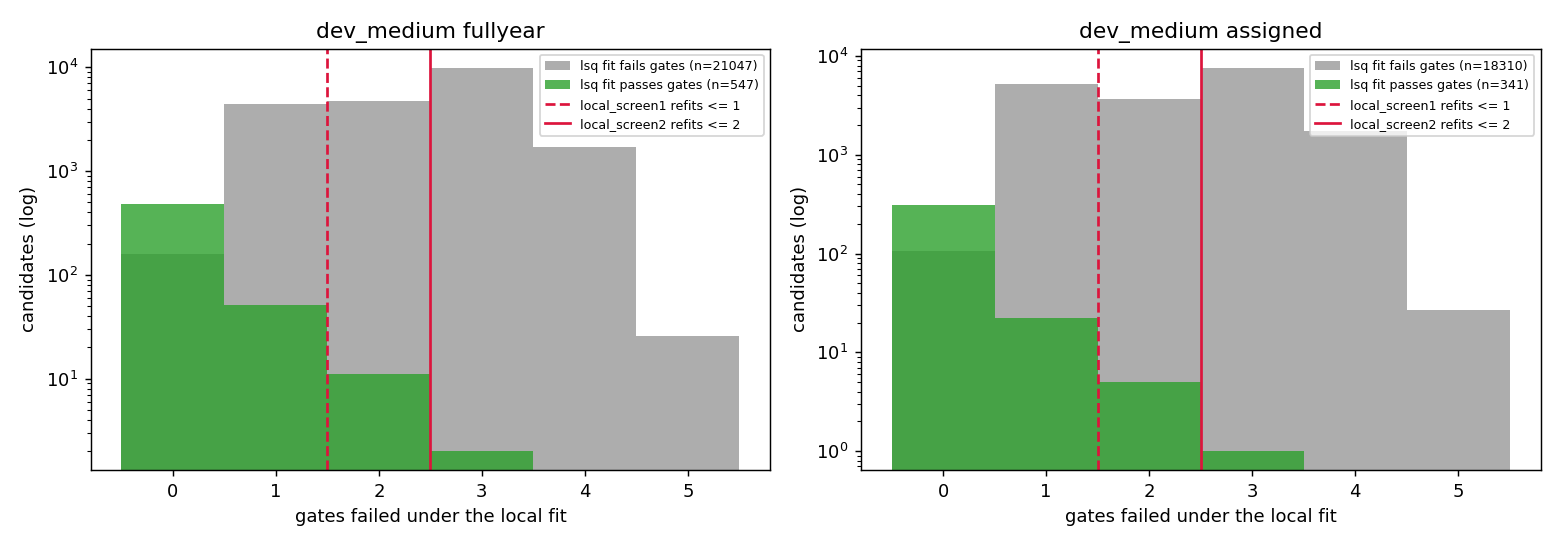

In [8]:
rec = A.fig_screen(SCR, FIG / 'fig_screen_threshold.png')
display(rec)
display(Image(FIG / 'fig_screen_threshold.png'))

### Why `local` behaves differently: gate failure rates

variant                         local  local_screen2  main (lsq)
mode     gate                                                   
assigned few_peaks_height       0.132          0.133       0.129
         frac_positive_heights  0.541          0.540       0.456
         frac_vertex_in_window  0.086          0.348       0.666
         half_lag_consistency   0.888          0.907       0.895
         mean_height_snr        0.718          0.704       0.635
         n_peaks                0.020          0.020       0.019
fullyear few_peaks_height       0.117          0.118       0.117
         frac_positive_heights  0.551          0.548       0.447
         frac_vertex_in_window  0.090          0.315       0.600
         half_lag_consistency   0.878          0.899       0.885
         mean_height_snr        0.759          0.747       0.665
         n_peaks                0.013          0.013       0.012

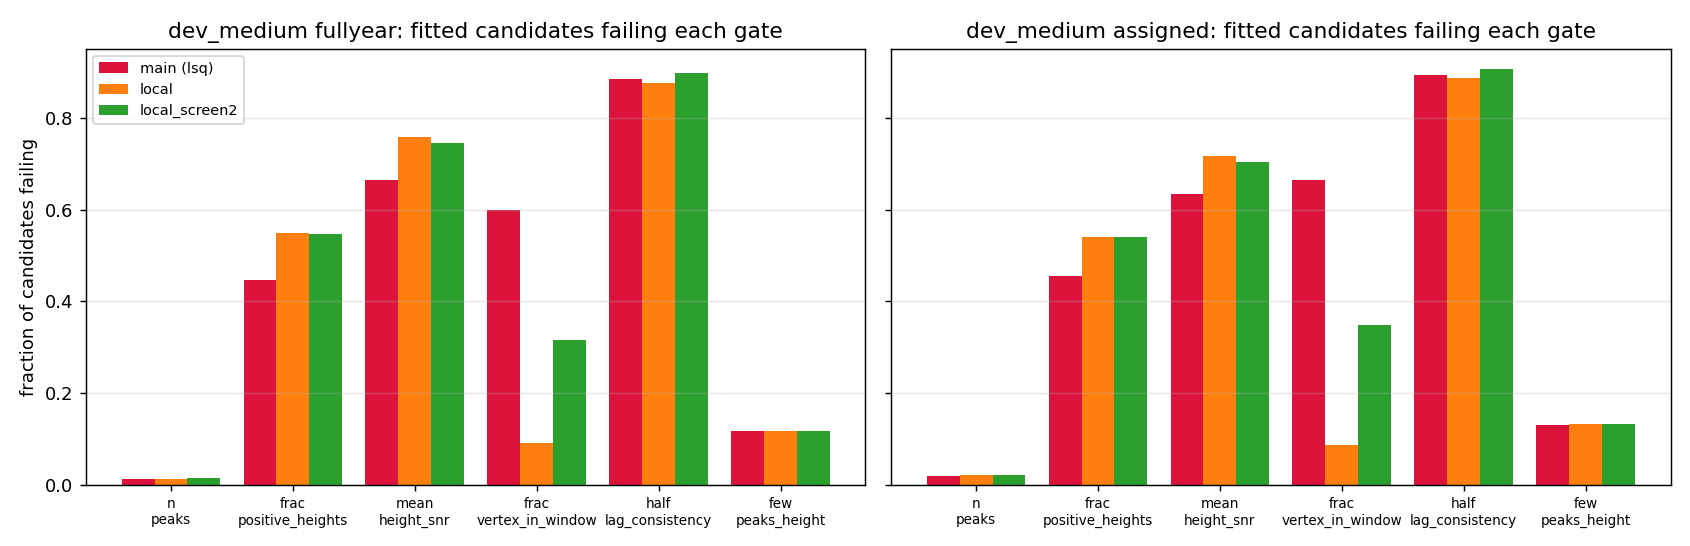

In [9]:
g = A.fig_gate_rates(SCR, FIG / 'fig_gate_fail_rates.png')
display(g.pivot_table(index=['mode','gate'], columns='variant', values='fail_rate').round(3))
display(Image(FIG / 'fig_gate_fail_rates.png'))

### CWT variants: wavelet recall vs wavelet-stage time

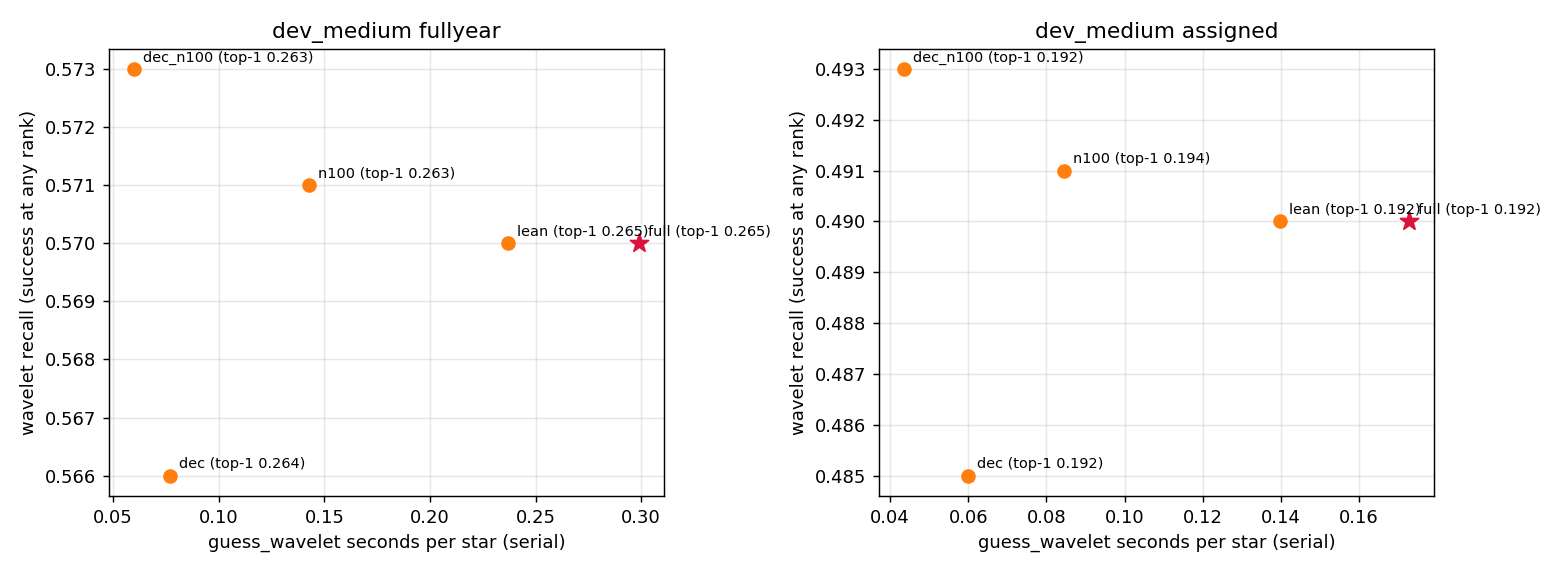

In [10]:
A.fig_cwt(met, tim, FIG / 'fig_cwt_variants.png')
display(Image(FIG / 'fig_cwt_variants.png'))

## Example light curves
Stars `local` loses / gains vs main, and the one star whose final period moves under local_screen2 (needs `data/smarts_dev`).

v_local__dec lost 5


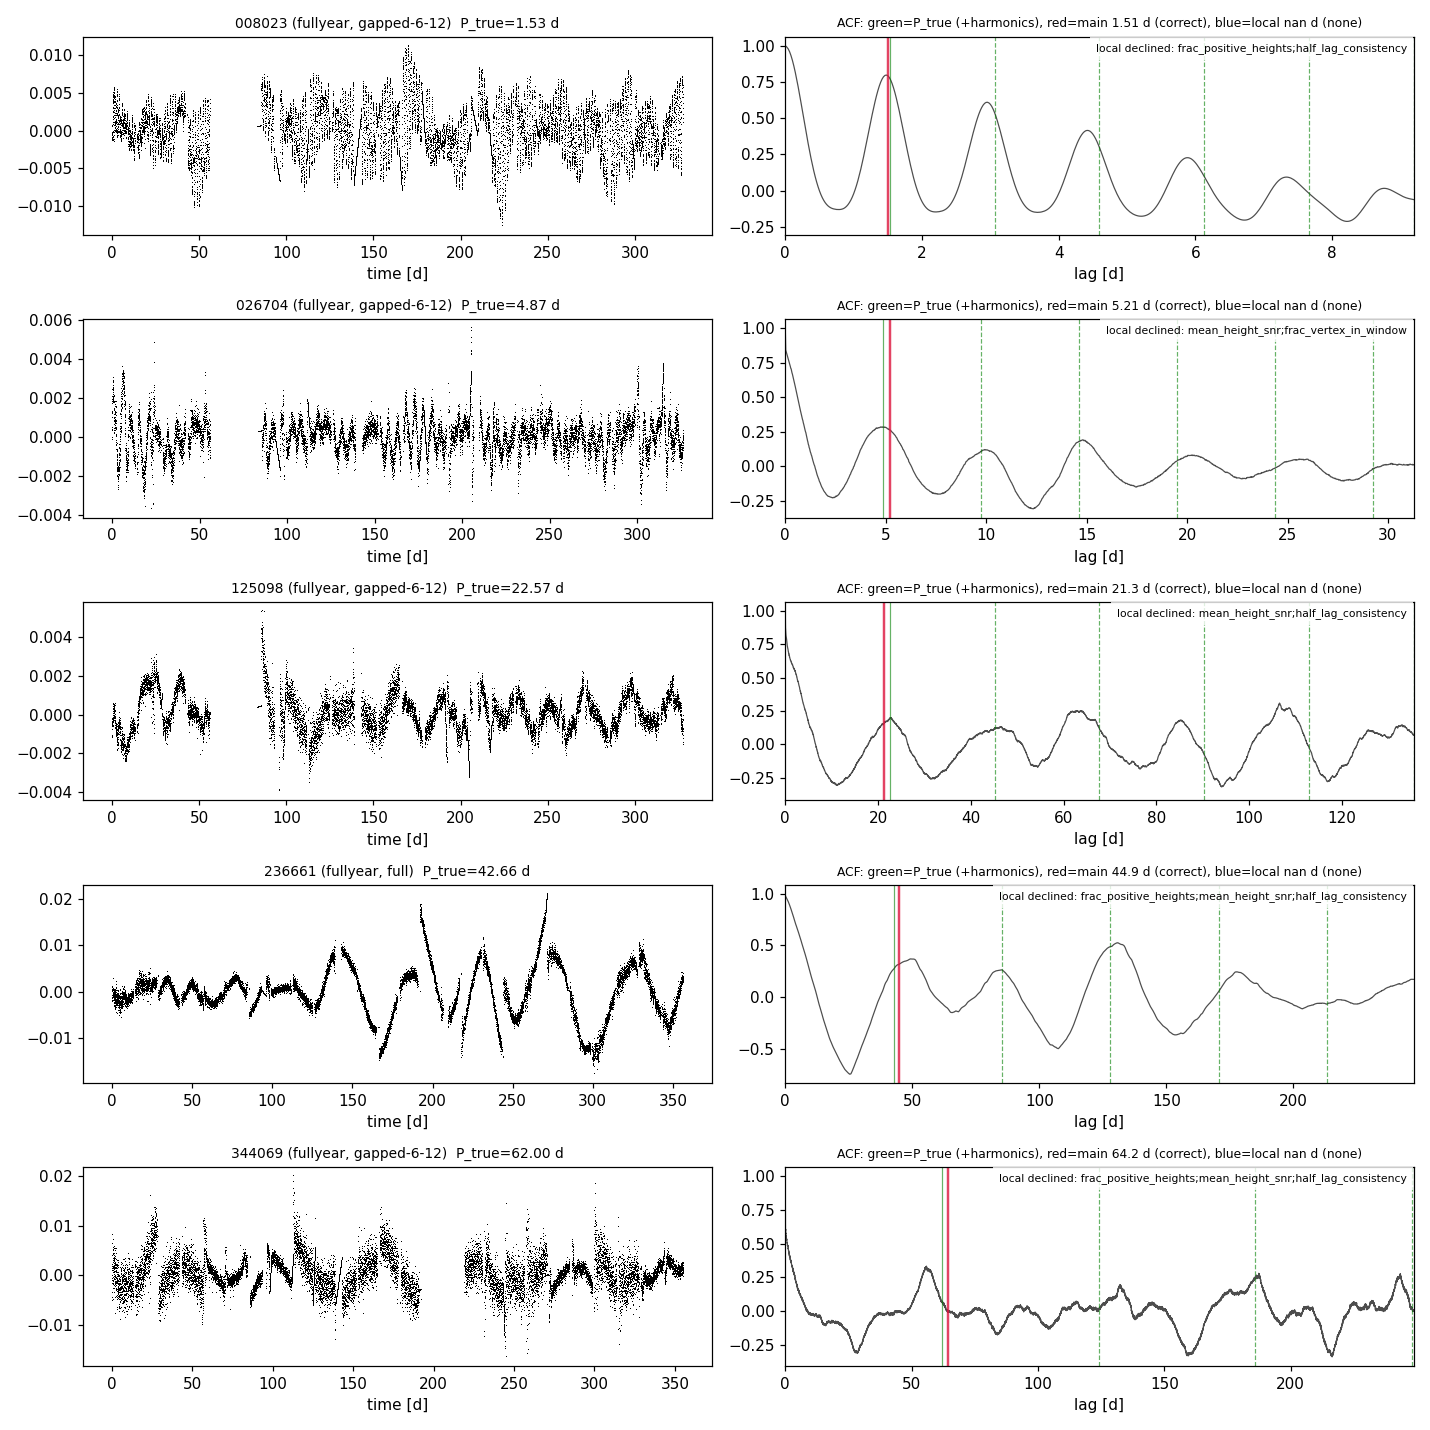

v_local__dec gained 5


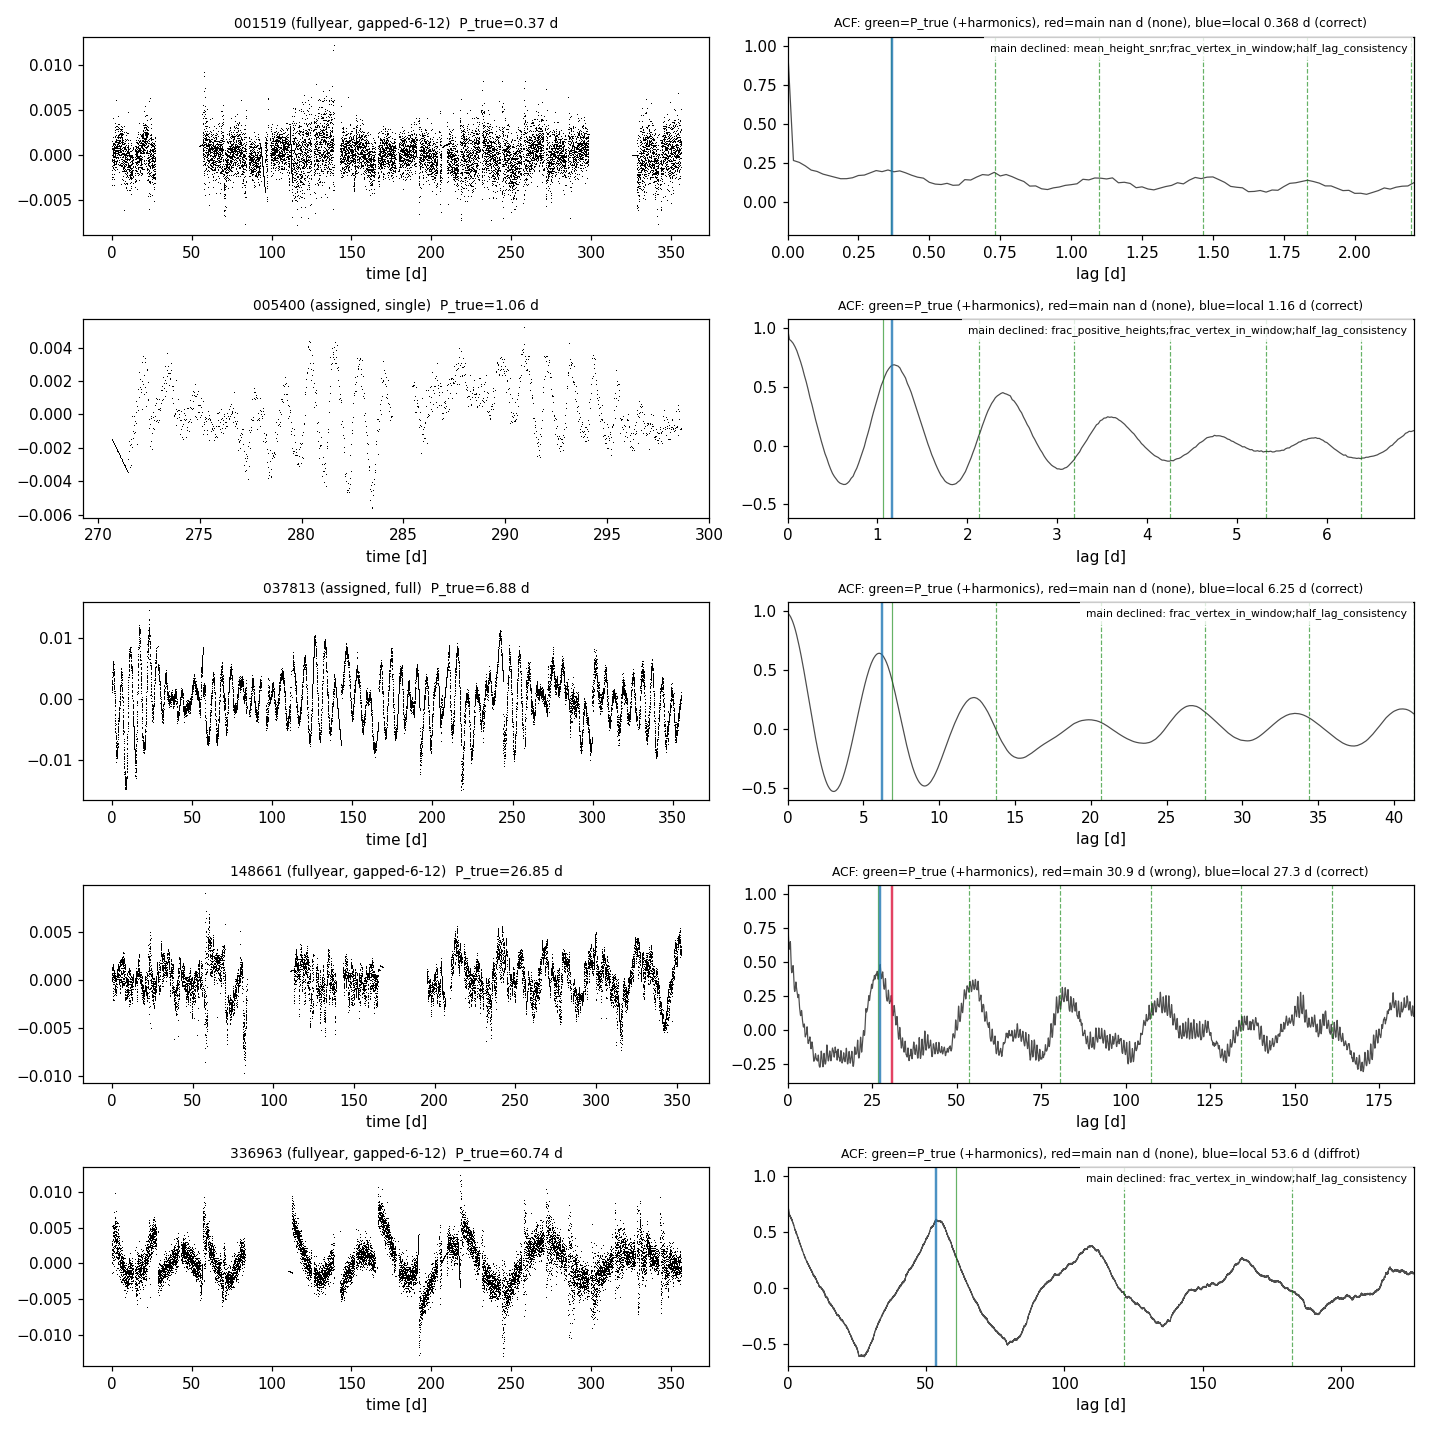

v_local_screen2 lost 0
v_local_screen2 gained 0


v_local_screen2 period_moved 1


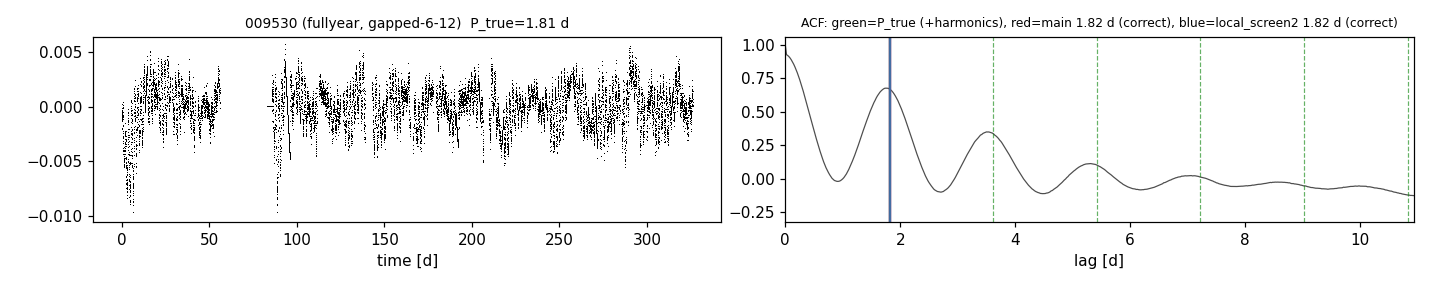

In [11]:
for run, kinds in (('v_local__dec', ('lost', 'gained')), ('v_local_screen2', ('lost', 'gained', 'period_moved'))):
    gl = pd.concat([A.gain_loss(SCR, run, m) for m in ('fullyear', 'assigned')])
    lab = A.run_name_to_variant(run)[0]
    for k in kinds:
        n = A.fig_examples(gl, lab, k, FIG / f'fig_examples_{lab}_{k}.png', n=5)
        print(run, k, n)
        if n:
            display(Image(FIG / f'fig_examples_{lab}_{k}.png'))